In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_excel("../data/Prac_Dataset3.xlsx", sheet_name="Job_Market_Trends")

df.shape 

(320, 10)

In [4]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
Job_ID                0
Quarter               0
Job_Role              0
Experience_Level      0
Location              0
Key_Skill             0
Years_Experience      0
Monthly_Salary_PHP    1
Employment_Type       1
Applicants_Count      0
dtype: int64


In [5]:
print("\nDuplicated Rows:")
print(df.duplicated().sum())


Duplicated Rows:
1


In [6]:
print("\nDuplicated Job IDs:")
print(df["Job_ID"].duplicated().sum())


Duplicated Job IDs:
1


In [7]:
print("\nNumerical Summary:")
display(df.describe())


Numerical Summary:


,Years_Experience,Monthly_Salary_PHP,Applicants_Count
count,320.000000,319.000000,320.000000
mean,4.771875,44458.492163,51.821875
std,3.179256,21162.201821,28.409061
min,-2.000000,15000.000000,1.000000
25%,2.000000,27399.000000,28.750000
50%,4.500000,39941.000000,52.000000
75%,8.000000,58773.000000,75.500000
max,10.000000,111066.000000,100.000000


In [8]:
print("Rows with Missing Values:")
display(df[df.isnull().any(axis=1)])

Rows with Missing Values:


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
24,J0025,2026-Q1,Web Developer,Entry-level,Metro Manila,Power BI,1,NaN,Part-time,71
240,J0241,2026-Q2,Data Analyst,Mid-level,Davao City,SQL,0,41642.0,NaN,33


In [9]:
print("\nDuplicated Records:")
display(df[df.duplicated(keep=False)])


Duplicated Records:


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
299,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59
300,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59


In [10]:
print("\nDuplicated Job IDs")
display(df[df["Job_ID"].duplicated(keep=False)])


Duplicated Job IDs


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
299,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59
300,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59


In [12]:
print("\nInvalid Years of Experience")
display(df[df["Years_Experience"] < 0])


Invalid Years of Experience


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
151,J0152,2026-Q1,Data Scientist,Senior,Davao City,Networking,-2,101660.0,Full-time,8


In [14]:
category_cols = [
    "Quarter",
    "Job_Role",
    "Experience_Level",
    "Location",
    "Key_Skill",
    "Employment_Type"    
]

for col in category_cols:
    print(f"\n-------{col}-------")
    print(df[col].value_counts(dropna=False))


-------Quarter-------
Quarter
2025-Q3    58
2026-Q2    57
2025-Q1    56
2026-Q1    53
2025-Q4    50
2025-Q2    45
2026-Q9     1
Name: count, dtype: int64

-------Job_Role-------
Job_Role
Network Administrator    61
Web Developer            52
Cybersecurity Analyst    47
Software Developer       46
Data Scientist           39
IT Support Specialist    37
Data Analyst             37
Data analyst              1
Name: count, dtype: int64

-------Experience_Level-------
Experience_Level
Senior         93
Junior         76
Mid-level      76
Entry-level    75
Name: count, dtype: int64

-------Location-------
Location
Cagayan de Oro    57
Remote            57
Iloilo City       56
Davao City        54
Metro Manila      50
Cebu City         45
metro manila       1
Name: count, dtype: int64

-------Key_Skill-------
Key_Skill
Networking         52
JavaScript         47
Cloud Computing    44
Cybersecurity      41
SQL                40
Excel              33
Power BI           32
Python             3

In [8]:

df = pd.read_excel(
    "../data/Prac_Dataset3.xlsx",
    sheet_name="Job_Market_Trends"
)

df_clean = df.copy()

df_clean["Job_Role"] = df_clean["Job_Role"].replace({
    "Data analyst" : "Data Analyst"
})

print(df_clean["Job_Role"].value_counts())

Job_Role
Network Administrator    61
Web Developer            52
Cybersecurity Analyst    47
Software Developer       46
Data Scientist           39
Data Analyst             38
IT Support Specialist    37
Name: count, dtype: int64


In [9]:
df_clean = df.copy()

df_clean["Location"] = df_clean["Location"].replace({
    "metro manila" : "Metro Manila"
})

print(df_clean["Location"].value_counts())

Location
Cagayan de Oro    57
Remote            57
Iloilo City       56
Davao City        54
Metro Manila      51
Cebu City         45
Name: count, dtype: int64


In [10]:
display(df_clean[df_clean["Quarter"] == "2026-Q9"])

,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
202,J0203,2026-Q9,Network Administrator,Mid-level,Davao City,JavaScript,5,36755.0,Internship,21


In [11]:
display(
    df_clean[df_clean["Employment_Type"].isna()]
)

,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
240,J0241,2026-Q2,Data Analyst,Mid-level,Davao City,SQL,0,41642.0,NaN,33


In [12]:
df_clean = df.copy()

df_clean["Job_Role"] = df_clean["Job_Role"].replace({
    "Data analyst": "Data Analyst"
})

df_clean["Location"] = df_clean["Location"].replace({
    "metro manila": "Metro Manila"
})

print("Data Analyst:",
      (df_clean["Job_Role"] == "Data Analyst").sum())

print("Metro Manila:",
      (df_clean["Location"] == "Metro Manila").sum())


Data Analyst: 38
Metro Manila: 51


In [13]:

valid_quarters = df_clean["Quarter"].str.fullmatch(
    r"\d{4}-Q[1-4]", na=False
)

df_clean.loc[~valid_quarters, "Quarter"] = np.nan

print("QUARTER VALUES AFTER CLEANING")
print(df_clean["Quarter"].value_counts(dropna=False))


QUARTER VALUES AFTER CLEANING
Quarter
2025-Q3    58
2026-Q2    57
2025-Q1    56
2026-Q1    53
2025-Q4    50
2025-Q2    45
NaN         1
Name: count, dtype: int64


In [14]:
df_clean["Employment_Type"] = (
    df_clean["Employment_Type"].fillna("Unknown")
)

print(df_clean["Employment_Type"].value_counts())


Employment_Type
Part-time     87
Internship    80
Full-time     77
Contract      75
Unknown        1
Name: count, dtype: int64


In [15]:
print("DATASET SHAPE:")
print(df_clean.shape)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df_clean.duplicated().sum())

print("\nINVALID EXPERIENCE:")
print((df_clean["Years_Experience"] < 0).sum())


DATASET SHAPE:
(320, 10)

MISSING VALUES:
Job_ID                0
Quarter               1
Job_Role              0
Experience_Level      0
Location              0
Key_Skill             0
Years_Experience      0
Monthly_Salary_PHP    1
Employment_Type       0
Applicants_Count      0
dtype: int64

DUPLICATE ROWS:
1

INVALID EXPERIENCE:
1


In [16]:

print("MISSING SALARY RECORD")
display(
    df_clean[df_clean["Monthly_Salary_PHP"].isna()]
)

print("\nNEGATIVE EXPERIENCE RECORD")
display(
    df_clean[df_clean["Years_Experience"] < 0]
)

print("\nDUPLICATE RECORDS")
display(
    df_clean[df_clean.duplicated(keep=False)]
)

MISSING SALARY RECORD


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
24,J0025,2026-Q1,Web Developer,Entry-level,Metro Manila,Power BI,1,NaN,Part-time,71



NEGATIVE EXPERIENCE RECORD


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
151,J0152,2026-Q1,Data Scientist,Senior,Davao City,Networking,-2,101660.0,Full-time,8



DUPLICATE RECORDS


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
299,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59
300,J0300,2025-Q1,Network Administrator,Senior,Davao City,SQL,5,57639.0,Full-time,59


In [17]:
print("Before:", df_clean.shape)

df_clean = df_clean.drop_duplicates().copy()

print("After:", df_clean.shape)
print("Remaining Duplicates:", df_clean.duplicated().sum())

Before: (320, 10)
After: (319, 10)
Remaining Duplicates: 0


In [18]:

similar_jobs = df_clean[
    (df_clean["Job_Role"] == "Web Developer") &
    (df_clean["Experience_Level"] == "Entry-level") &
    (df_clean["Monthly_Salary_PHP"].notna())
]

display(similar_jobs[[
    "Job_ID",
    "Job_Role",
    "Experience_Level",
    "Monthly_Salary_PHP"
]])

print("Comparable records:", len(similar_jobs))
print("Median salary:", similar_jobs["Monthly_Salary_PHP"].median())


,Job_ID,Job_Role,Experience_Level,Monthly_Salary_PHP
42,J0043,Web Developer,Entry-level,23083.0
102,J0103,Web Developer,Entry-level,15000.0
115,J0116,Web Developer,Entry-level,25809.0
132,J0133,Web Developer,Entry-level,18684.0
149,J0150,Web Developer,Entry-level,27684.0
188,J0189,Web Developer,Entry-level,22120.0
200,J0201,Web Developer,Entry-level,18343.0
250,J0251,Web Developer,Entry-level,33313.0
255,J0256,Web Developer,Entry-level,22371.0
261,J0262,Web Developer,Entry-level,25321.0


Comparable records: 15
Median salary: 23083.0


In [ ]:
median_salary = similar_jobs["Monthly_Salary_PHP"].median()

if pd.notna(median_salary):
    df_clean.loc[
        df_clean["Job_ID"] == "J0025",
        "Monthly_Salary_PHP"
    ] = median_salary

display(df_clean[df_clean["Job_ID"] == "J0025"])


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
24,J0025,2026-Q1,Web Developer,Entry-level,Metro Manila,Power BI,1,23083.0,Part-time,71


In [20]:
similar_experience = df_clean[
    (df_clean["Job_Role"] == "Data Scientist") &
    (df_clean["Experience_Level"] == "Senior") &
    (df_clean["Years_Experience"] >= 0)
]

print("Comparable records:", len(similar_experience))

median_experience = similar_experience["Years_Experience"].median()

print("Median experience:", median_experience)

if pd.notna(median_experience):
    df_clean.loc[
        df_clean["Job_ID"] == "J0152",
        "Years_Experience"
    ] = median_experience

display(df_clean[df_clean["Job_ID"] == "J0152"])

Comparable records: 12
Median experience: 2.0


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
151,J0152,2026-Q1,Data Scientist,Senior,Davao City,Networking,2,101660.0,Full-time,8


In [ ]:
print("FINAL DATASET SHAPE:")
print(df_clean.shape)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df_clean.duplicated().sum())

print("\nINVALID EXPERIENCE:")
print((df_clean["Years_Experience"] < 0).sum())

print("\nINVALID SALARY:")
print((df_clean["Monthly_Salary_PHP"] <= 0).sum())

FINAL DATASET SHAPE:
(319, 10)

MISSING VALUES:
Job_ID                0
Quarter               1
Job_Role              0
Experience_Level      0
Location              0
Key_Skill             0
Years_Experience      0
Monthly_Salary_PHP    0
Employment_Type       0
Applicants_Count      0
dtype: int64

DUPLICATE ROWS:
0

INVALID EXPERIENCE:
0

INVALID SALARY:
0


In [22]:
from pathlib import Path

output_folder = Path("../output")
output_folder.mkdir(parents=True, exist_ok=True)

df_clean.to_excel(
    output_folder / "Job_Market_Trends_Cleaned.xlsx",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total records:", len(df_clean))


Cleaned dataset saved successfully!
Total records: 319


In [23]:
#7.	Which IT roles and skills appear most frequently in the dataset? State how frequency is measured.
job_counts = df_clean["Job_Role"].value_counts()

print("JOB LISTINGS BY ROLE")
print(job_counts)

job_percent = (
    job_counts / len(df_clean) * 100
).round(2)

print("\nPERCENTAGE OF TOTAL LISTINGS")
print(job_percent)


JOB LISTINGS BY ROLE
Job_Role
Network Administrator    60
Web Developer            52
Cybersecurity Analyst    47
Software Developer       46
Data Scientist           39
Data Analyst             38
IT Support Specialist    37
Name: count, dtype: int64

PERCENTAGE OF TOTAL LISTINGS
Job_Role
Network Administrator    18.81
Web Developer            16.30
Cybersecurity Analyst    14.73
Software Developer       14.42
Data Scientist           12.23
Data Analyst             11.91
IT Support Specialist    11.60
Name: count, dtype: float64


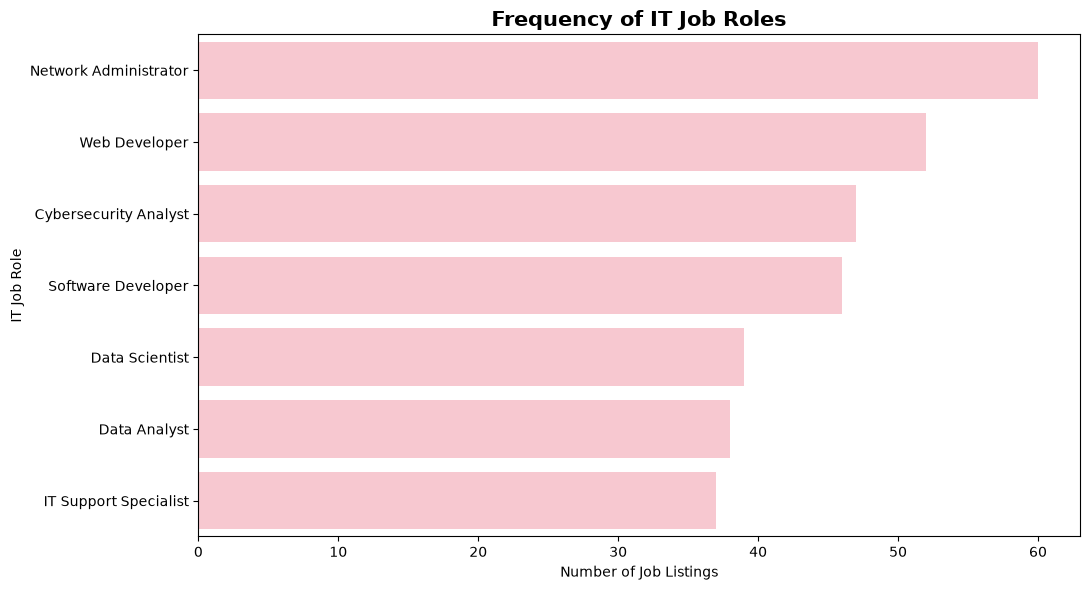

In [24]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_counts.values,
    y=job_counts.index,
    color="pink"
)

plt.title(
    "Frequency of IT Job Roles",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Job Listings")
plt.ylabel("IT Job Role")

plt.tight_layout()
plt.show()


In [25]:
skill_counts = df_clean["Key_Skill"].value_counts()

print("MOST FREQUENTLY LISTED IT SKILLS")
print(skill_counts)

skill_percent = (
    skill_counts / len(df_clean) * 100
).round(2)

print("\nSKILL PERCENTAGES")
print(skill_percent)

MOST FREQUENTLY LISTED IT SKILLS
Key_Skill
Networking         52
JavaScript         47
Cloud Computing    44
Cybersecurity      41
SQL                39
Excel              33
Power BI           32
Python             31
Name: count, dtype: int64

SKILL PERCENTAGES
Key_Skill
Networking         16.30
JavaScript         14.73
Cloud Computing    13.79
Cybersecurity      12.85
SQL                12.23
Excel              10.34
Power BI           10.03
Python              9.72
Name: count, dtype: float64


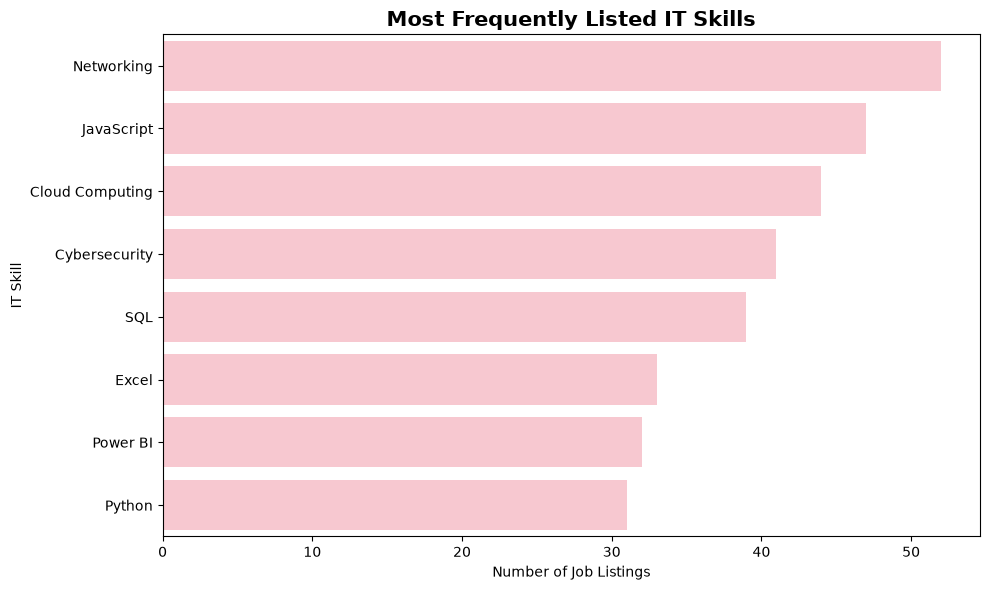

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=skill_counts.values,
    y=skill_counts.index,
    color="pink"
)

plt.title(
    "Most Frequently Listed IT Skills",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Job Listings")
plt.ylabel("IT Skill")

plt.tight_layout()
plt.show()


In [28]:
#8.	How do posted monthly salaries differ by role, experience level, and location?
salary_by_role = (
    df_clean.groupby("Job_Role")["Monthly_Salary_PHP"]
    .median()
    .sort_values(ascending=False)
)

print("MEDIAN MONTHLY SALARY BY JOB ROLE")
print(salary_by_role)


MEDIAN MONTHLY SALARY BY JOB ROLE
Job_Role
Data Scientist           73792.0
Cybersecurity Analyst    47427.0
Software Developer       46476.0
Network Administrator    38663.0
Web Developer            34473.0
Data Analyst             32741.0
IT Support Specialist    23240.0
Name: Monthly_Salary_PHP, dtype: float64


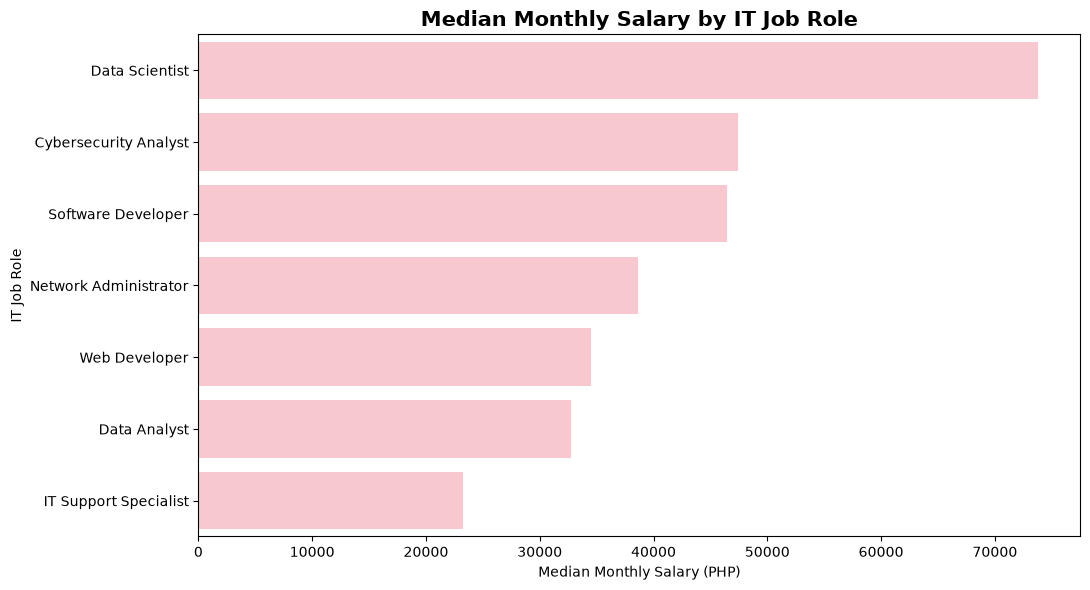

In [29]:

plt.figure(figsize=(11, 6))

sns.barplot(
    x=salary_by_role.values,
    y=salary_by_role.index,
    color="pink"
)

plt.title(
    "Median Monthly Salary by IT Job Role",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Median Monthly Salary (PHP)")
plt.ylabel("IT Job Role")

plt.tight_layout()
plt.show()


In [30]:
level_order = [
    "Entry-level",
    "Junior",
    "Mid-level",
    "Senior"
]

salary_by_level = (
    df_clean.groupby("Experience_Level")["Monthly_Salary_PHP"]
    .median()
    .reindex(level_order)
)

print("MEDIAN SALARY BY EXPERIENCE LEVEL")
print(salary_by_level)


MEDIAN SALARY BY EXPERIENCE LEVEL
Experience_Level
Entry-level    22781.0
Junior         30438.0
Mid-level      44260.5
Senior         64235.5
Name: Monthly_Salary_PHP, dtype: float64


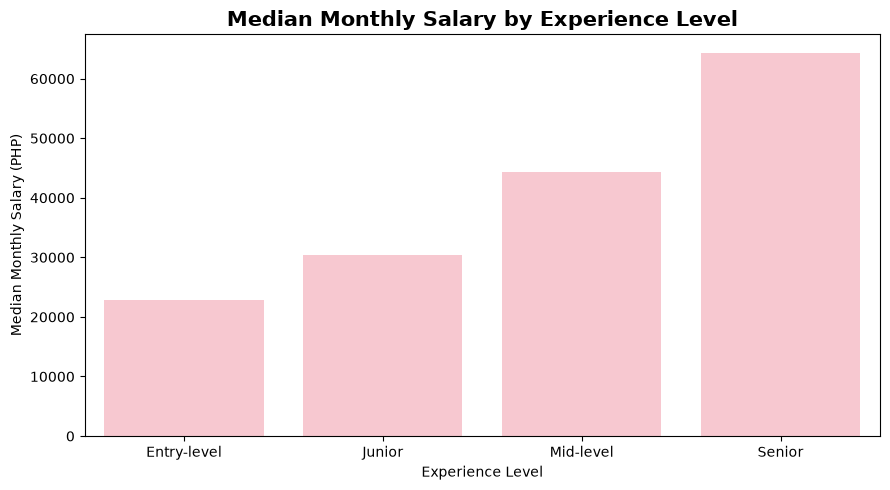

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=salary_by_level.index,
    y=salary_by_level.values,
    color="pink"
)

plt.title(
    "Median Monthly Salary by Experience Level",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Experience Level")
plt.ylabel("Median Monthly Salary (PHP)")

plt.tight_layout()
plt.show()


In [33]:
salary_by_location = (
    df_clean.groupby("Location")["Monthly_Salary_PHP"]
    .median()
    .sort_values(ascending=False)
)

print("MEDIAN SALARY BY LOCATION")
print(salary_by_location)


MEDIAN SALARY BY LOCATION
Location
Davao City        44806.0
Cagayan de Oro    41605.0
Remote            40692.0
Cebu City         39303.0
Iloilo City       36017.5
Metro Manila      34333.0
Name: Monthly_Salary_PHP, dtype: float64


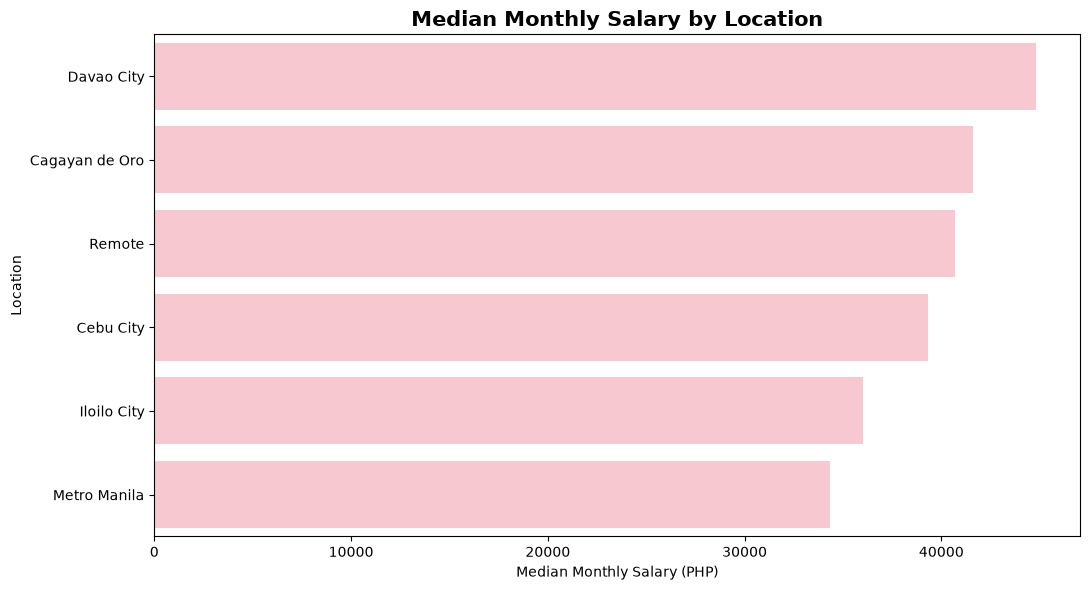

In [35]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=salary_by_location.values,
    y=salary_by_location.index,
    color="pink"
)

plt.title(
    "Median Monthly Salary by Location",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Median Monthly Salary (PHP)")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

In [36]:
#Are years of experience and salary associated?
correlation = df_clean[
    ["Years_Experience", "Monthly_Salary_PHP"]
].corr()

print("CORRELATION MATRIX")
print(correlation)

r = correlation.loc[
    "Years_Experience",
    "Monthly_Salary_PHP"
]

print(f"\nExperience-Salary Correlation: {r:.3f}")


CORRELATION MATRIX
                    Years_Experience  Monthly_Salary_PHP
Years_Experience            1.000000           -0.071131
Monthly_Salary_PHP         -0.071131            1.000000

Experience-Salary Correlation: -0.071


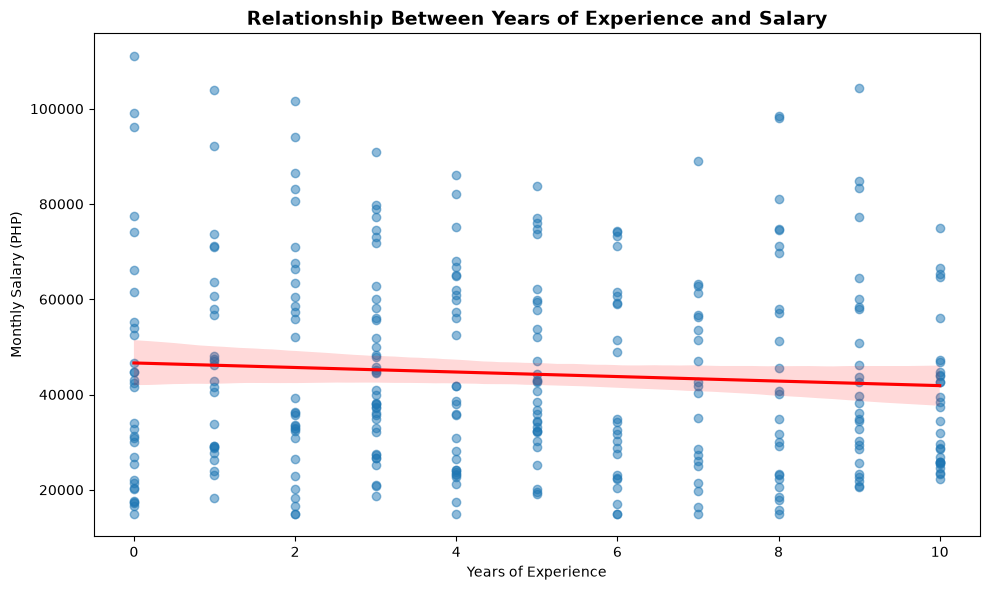

In [37]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x="Years_Experience",
    y="Monthly_Salary_PHP",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title(
    "Relationship Between Years of Experience and Salary",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Years of Experience")
plt.ylabel("Monthly Salary (PHP)")

plt.tight_layout()
plt.show()


In [38]:
role_correlations = (
    df_clean.groupby("Job_Role")
    .apply(
        lambda group: group["Years_Experience"].corr(
            group["Monthly_Salary_PHP"]
        ),
        include_groups=False
    )
    .sort_values(ascending=False)
)

print("EXPERIENCE-SALARY CORRELATION BY ROLE")
print(role_correlations)


EXPERIENCE-SALARY CORRELATION BY ROLE
Job_Role
IT Support Specialist    0.369966
Data Analyst             0.086431
Cybersecurity Analyst    0.039097
Network Administrator   -0.089668
Web Developer           -0.099542
Software Developer      -0.119563
Data Scientist          -0.250630
dtype: float64


In [39]:
level_summary = (
    df_clean.groupby("Experience_Level")
    .agg(
        Job_Count=("Job_ID", "count"),
        Median_Years=("Years_Experience", "median"),
        Median_Salary=("Monthly_Salary_PHP", "median")
    )
    .reindex([
        "Entry-level",
        "Junior",
        "Mid-level",
        "Senior"
    ])
)

display(level_summary)


,Job_Count,Median_Years,Median_Salary
Experience_Level,,,
Entry-level,75,4.0,22781.0
Junior,76,5.0,30438.0
Mid-level,76,5.0,44260.5
Senior,92,4.0,64235.5


In [40]:
level_correlations = (
    df_clean.groupby("Experience_Level")
    .apply(
        lambda group: group["Years_Experience"].corr(
            group["Monthly_Salary_PHP"]
        ),
        include_groups=False
    )
)

print("EXPERIENCE-SALARY CORRELATION BY LEVEL")
print(level_correlations.round(3))


EXPERIENCE-SALARY CORRELATION BY LEVEL
Experience_Level
Entry-level   -0.019
Junior         0.008
Mid-level     -0.071
Senior        -0.147
dtype: float64


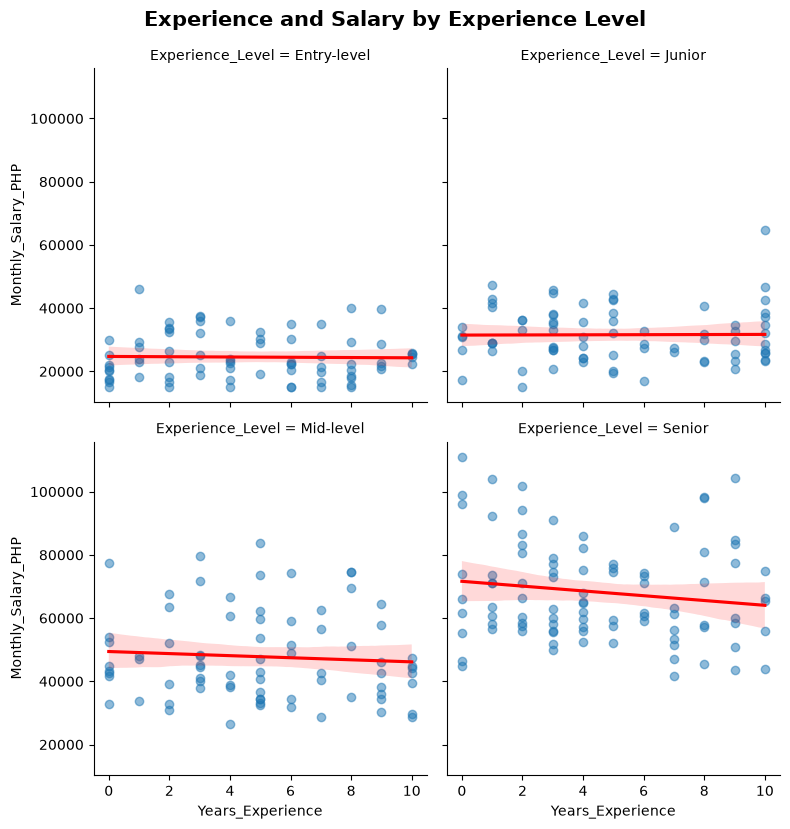

In [ ]:
sns.lmplot(
    data=df_clean,
    x="Years_Experience",
    y="Monthly_Salary_PHP",
    col="Experience_Level",
    col_order=[
        "Entry-level",
        "Junior",
        "Mid-level",
        "Senior"
    ],
    col_wrap=2,
    height=4,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.suptitle(
    "Experience and Salary by Experience Level",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.show()
3

In [42]:
#10.How do employment types and applicant counts vary across roles or quarters?
employment_by_role = pd.crosstab(
    df_clean["Job_Role"],
    df_clean["Employment_Type"]
)

print("EMPLOYMENT TYPES BY JOB ROLE")
display(employment_by_role)


EMPLOYMENT TYPES BY JOB ROLE


Employment_Type,Contract,Full-time,Internship,Part-time,Unknown
Job_Role,,,,,
Cybersecurity Analyst,9,7,13,18,0
Data Analyst,13,11,8,5,1
Data Scientist,7,11,10,11,0
IT Support Specialist,4,11,7,15,0
Network Administrator,13,13,21,13,0
Software Developer,17,8,8,13,0
Web Developer,12,15,13,12,0


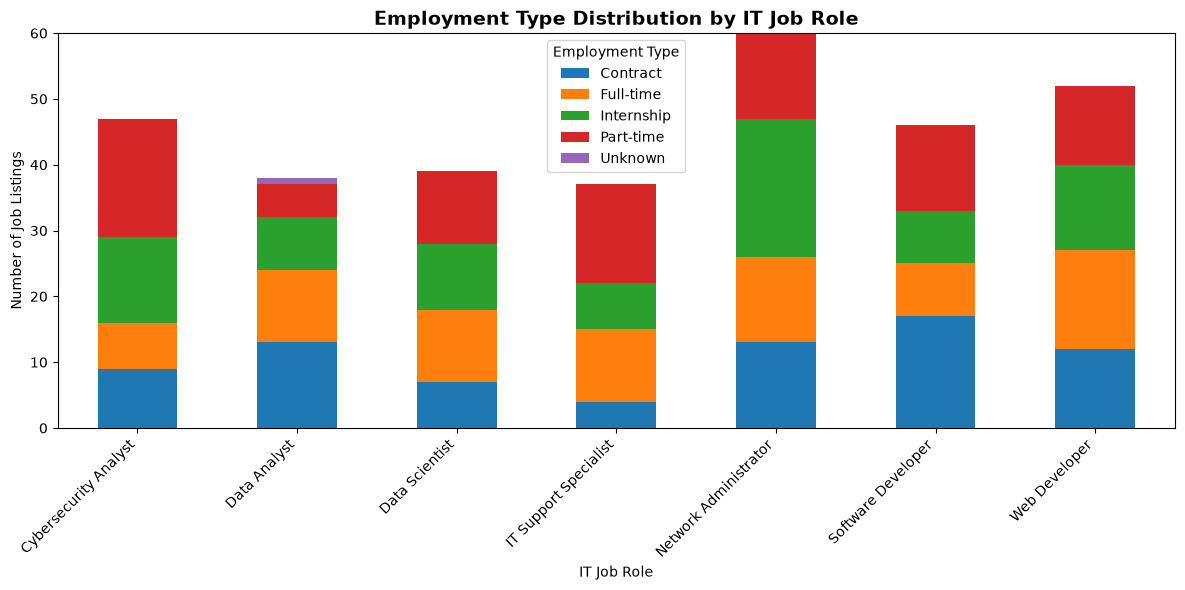

In [43]:
employment_by_role.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title(
    "Employment Type Distribution by IT Job Role",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("IT Job Role")
plt.ylabel("Number of Job Listings")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Employment Type")

plt.tight_layout()
plt.show()


In [44]:
applicants_by_role = (
    df_clean.groupby("Job_Role")
    .agg(
        Job_Count=("Job_ID", "count"),
        Total_Applicants=("Applicants_Count", "sum"),
        Median_Applicants=("Applicants_Count", "median")
    )
    .sort_values(
        "Median_Applicants",
        ascending=False
    )
)

print("APPLICANT STATISTICS BY JOB ROLE")
display(applicants_by_role)


APPLICANT STATISTICS BY JOB ROLE


,Job_Count,Total_Applicants,Median_Applicants
Job_Role,,,
Software Developer,46,2512,57.0
Web Developer,52,2709,56.5
Cybersecurity Analyst,47,2571,55.0
Network Administrator,60,3140,54.0
Data Scientist,39,2069,54.0
Data Analyst,38,2067,50.5
IT Support Specialist,37,1456,32.0


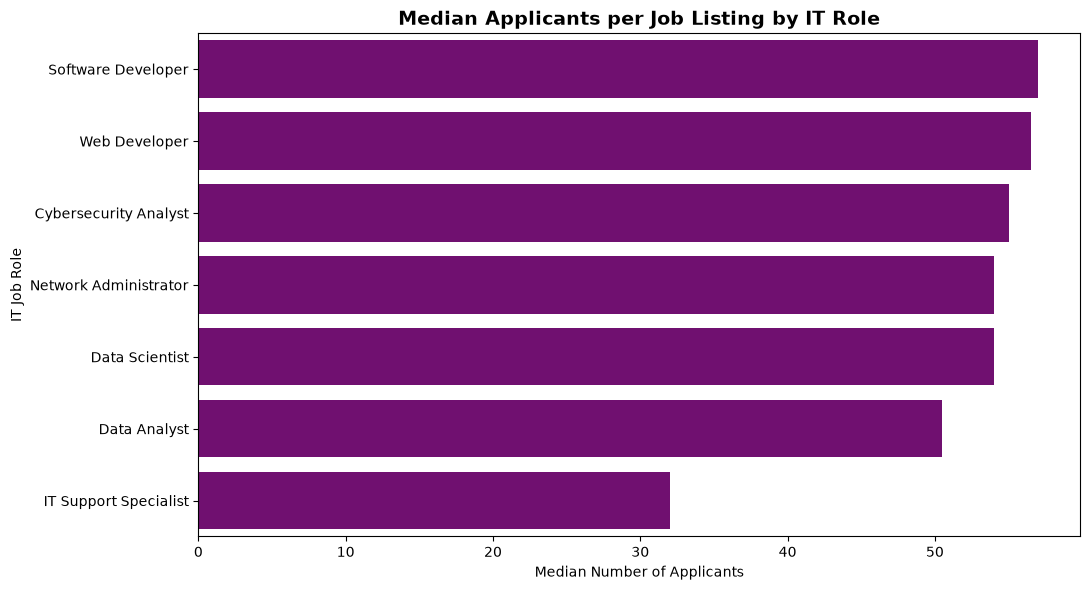

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=applicants_by_role["Median_Applicants"].values,
    y=applicants_by_role.index,
    color="purple"
)

plt.title(
    "Median Applicants per Job Listing by IT Role",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Median Number of Applicants")
plt.ylabel("IT Job Role")

plt.tight_layout()
plt.show()


In [47]:
#How do IT job listings change across quarters, and which roles show changes over time?
quarter_order = [
    "2025-Q1",
    "2025-Q2",
    "2025-Q3",
    "2025-Q4",
    "2026-Q1",
    "2026-Q2"
]

quarter_counts = (
    df_clean["Quarter"]
    .value_counts()
    .reindex(quarter_order)
)

print("JOB LISTINGS BY QUARTER")
print(quarter_counts)


JOB LISTINGS BY QUARTER
Quarter
2025-Q1    55
2025-Q2    45
2025-Q3    58
2025-Q4    50
2026-Q1    53
2026-Q2    57
Name: count, dtype: int64


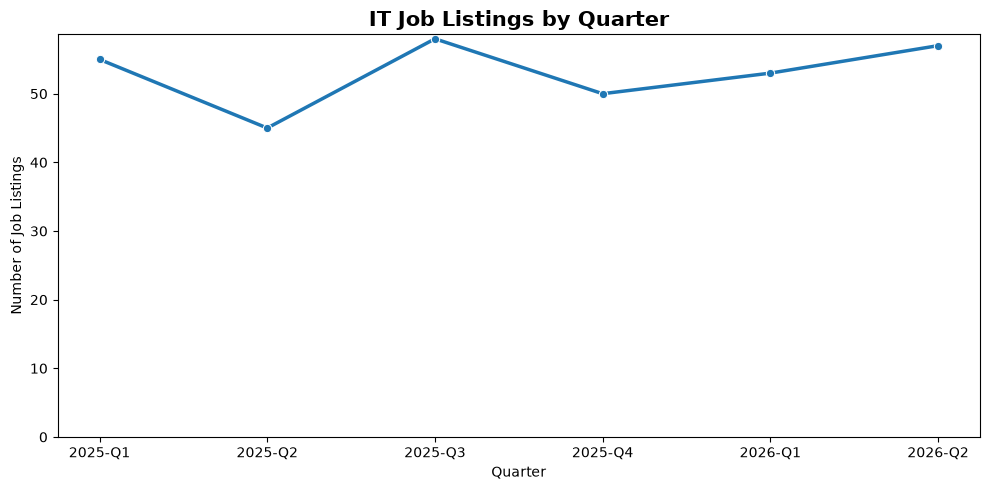

In [48]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=quarter_counts.index,
    y=quarter_counts.values,
    marker="o",
    linewidth=2.5
)

plt.title(
    "IT Job Listings by Quarter",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Quarter")
plt.ylabel("Number of Job Listings")
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()


In [50]:
quarter_order = [
    "2025-Q1",
    "2025-Q2",
    "2025-Q3",
    "2025-Q4",
    "2026-Q1",
    "2026-Q2"
]

quarterly_roles = pd.crosstab(
    df_clean["Quarter"],
    df_clean["Job_Role"]
)

quarterly_roles = quarterly_roles.reindex(
    quarter_order,
    fill_value=0
)

print("QUARTERLY JOB ROLE DISTRIBUTION")
display(quarterly_roles)


QUARTERLY JOB ROLE DISTRIBUTION


Job_Role,Cybersecurity Analyst,Data Analyst,Data Scientist,IT Support Specialist,Network Administrator,Software Developer,Web Developer
Quarter,,,,,,,
2025-Q1,13,6,9,4,9,5,9
2025-Q2,4,2,5,7,7,8,12
2025-Q3,7,10,5,8,11,9,8
2025-Q4,6,7,6,6,11,9,5
2026-Q1,7,8,7,4,9,10,8
2026-Q2,10,5,7,8,12,5,10


In [51]:
role_changes = pd.DataFrame({
    "2025_Q1": quarterly_roles.loc["2025-Q1"],
    "2026_Q2": quarterly_roles.loc["2026-Q2"]
})

role_changes["Change"] = (
    role_changes["2026_Q2"] -
    role_changes["2025_Q1"]
)

role_changes = role_changes.sort_values(
    "Change",
    ascending=False
)

print("CHANGE IN JOB LISTINGS BY ROLE")
display(role_changes)


CHANGE IN JOB LISTINGS BY ROLE


,2025_Q1,2026_Q2,Change
Job_Role,,,
IT Support Specialist,4,8,4
Network Administrator,9,12,3
Web Developer,9,10,1
Software Developer,5,5,0
Data Analyst,6,5,-1
Data Scientist,9,7,-2
Cybersecurity Analyst,13,10,-3


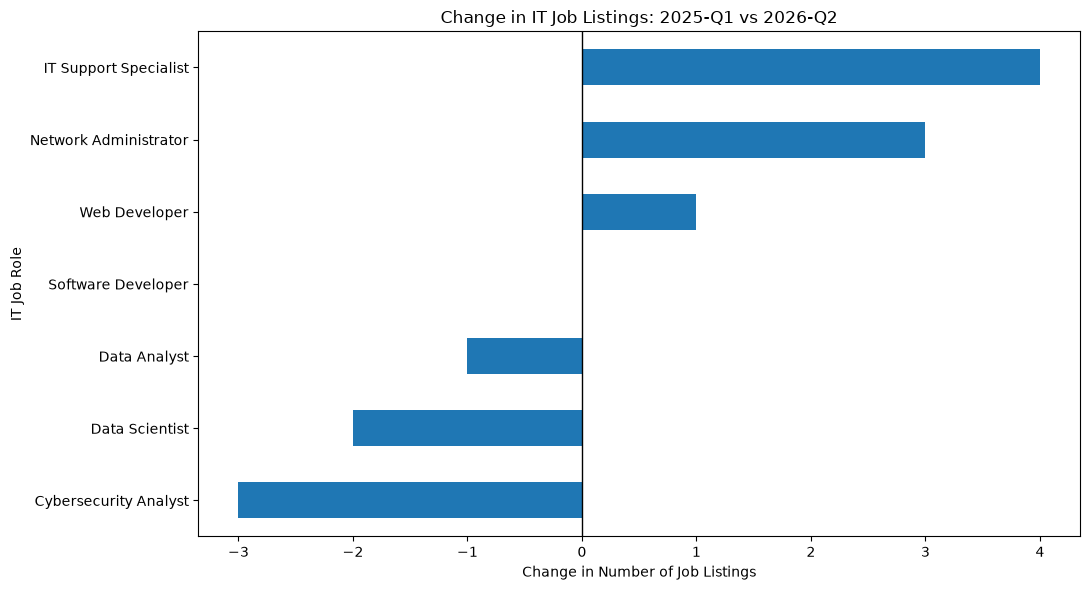

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

role_changes["Change"].sort_values().plot(
    kind="barh"
)

plt.title("Change in IT Job Listings: 2025-Q1 vs 2026-Q2")
plt.xlabel("Change in Number of Job Listings")
plt.ylabel("IT Job Role")

plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()

plt.savefig("../charts/job_role_changes.png", dpi=300)
plt.show()


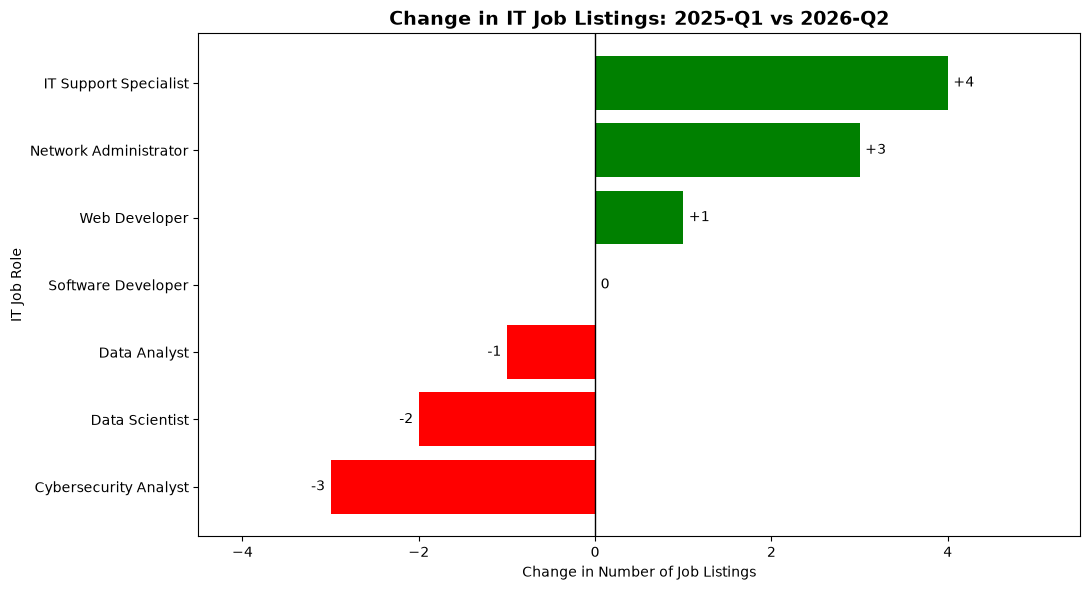

In [53]:

import matplotlib.pyplot as plt

changes = role_changes["Change"].sort_values()

colors = [
    "green" if value > 0 else
    "red" if value < 0 else
    "gray"
    for value in changes
]

plt.figure(figsize=(11, 6))

bars = plt.barh(
    changes.index,
    changes.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.bar_label(
    bars,
    labels=[f"{v:+d}" if v != 0 else "0"
            for v in changes],
    padding=4
)

plt.title(
    "Change in IT Job Listings: 2025-Q1 vs 2026-Q2",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Change in Number of Job Listings")
plt.ylabel("IT Job Role")
plt.xlim(-4.5, 5.5)

plt.tight_layout()
plt.savefig("../charts/job_role_changes_final.png", dpi=300)
plt.show()


In [54]:

print("FINAL ANALYSIS SUMMARY")

print("\nTotal Records:", len(df_clean))

print("\nTOP 5 IT JOB ROLES")
print(df_clean["Job_Role"].value_counts().head(5))

print("\nMEDIAN SALARY BY EXPERIENCE LEVEL")
print(
    df_clean.groupby("Experience_Level")
    ["Monthly_Salary_PHP"].median()
    .sort_values(ascending=False)
)

print("\nMEDIAN APPLICANTS BY JOB ROLE")
print(
    df_clean.groupby("Job_Role")
    ["Applicants_Count"].median()
    .sort_values(ascending=False)
)

print("\nJOB LISTINGS BY QUARTER")
print(
    df_clean["Quarter"].value_counts()
    .sort_index()
)

print("\nMISSING VALUES")
print(df_clean.isnull().sum())


FINAL ANALYSIS SUMMARY

Total Records: 319

TOP 5 IT JOB ROLES
Job_Role
Network Administrator    60
Web Developer            52
Cybersecurity Analyst    47
Software Developer       46
Data Scientist           39
Name: count, dtype: int64

MEDIAN SALARY BY EXPERIENCE LEVEL
Experience_Level
Senior         64235.5
Mid-level      44260.5
Junior         30438.0
Entry-level    22781.0
Name: Monthly_Salary_PHP, dtype: float64

MEDIAN APPLICANTS BY JOB ROLE
Job_Role
Software Developer       57.0
Web Developer            56.5
Cybersecurity Analyst    55.0
Network Administrator    54.0
Data Scientist           54.0
Data Analyst             50.5
IT Support Specialist    32.0
Name: Applicants_Count, dtype: float64

JOB LISTINGS BY QUARTER
Quarter
2025-Q1    55
2025-Q2    45
2025-Q3    58
2025-Q4    50
2026-Q1    53
2026-Q2    57
Name: count, dtype: int64

MISSING VALUES
Job_ID                0
Quarter               1
Job_Role              0
Experience_Level      0
Location              0
Key_Skill

In [55]:

print("RECORD WITH MISSING QUARTER")
display(df_clean[df_clean["Quarter"].isna()])


RECORD WITH MISSING QUARTER


,Job_ID,Quarter,Job_Role,Experience_Level,Location,Key_Skill,Years_Experience,Monthly_Salary_PHP,Employment_Type,Applicants_Count
202,J0203,NaN,Network Administrator,Mid-level,Davao City,JavaScript,5,36755.0,Internship,21


In [56]:
df_final = df_clean.copy()

df_quarterly = df_final.dropna(subset=["Quarter"]).copy()

print("FINAL DATASET:", df_final.shape)
print("QUARTERLY DATASET:", df_quarterly.shape)

print("\nMISSING QUARTERS IN QUARTERLY DATASET:")
print(df_quarterly["Quarter"].isna().sum())


FINAL DATASET: (319, 10)
QUARTERLY DATASET: (318, 10)

MISSING QUARTERS IN QUARTERLY DATASET:
0


In [57]:

df_final.to_excel(
    "../output/Job_Market_Trends_Final.xlsx",
    index=False
)

df_quarterly.to_excel(
    "../output/Job_Market_Quarterly.xlsx",
    index=False
)

print("Both datasets saved successfully!")


Both datasets saved successfully!
